In [1]:
import sys

print(sys.executable)

C:\Users\ryanr\Desktop\real-time-e2e-ml-system-project\.venv\Scripts\python.exe


In [2]:

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# --------------------------------------------------
# 1. FIND THE MAIN A1 PROJECT DIRECTORY
# --------------------------------------------------

current_directory = Path.cwd().resolve()

PROJECT_ROOT = None

for directory in (
    current_directory,
    *current_directory.parents,
):
    if (directory / "pyproject.toml").is_file():
        PROJECT_ROOT = directory
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate the A1 project root. "
        "Expected to find pyproject.toml in this "
        "directory or one of its parent directories."
    )


# --------------------------------------------------
# 2. DEFINE THE CORRECT DATASET LOCATION
# --------------------------------------------------

DATA_DIRECTORY = (
    PROJECT_ROOT / "data" / "raw" / "UNSW-NB15"
)

FEATURES_FILE = (
    DATA_DIRECTORY / "NUSW-NB15_features.csv"
)

DATA_FILES = [
    "UNSW-NB15_1.csv",
    "UNSW-NB15_2.csv",
    "UNSW-NB15_3.csv",
    "UNSW-NB15_4.csv",
]


# --------------------------------------------------
# 3. VERIFY THAT ALL REQUIRED FILES EXIST
# --------------------------------------------------

if not FEATURES_FILE.is_file():
    raise FileNotFoundError(
        f"Feature metadata not found: {FEATURES_FILE}"
    )

for filename in DATA_FILES:
    file_path = DATA_DIRECTORY / filename

    if not file_path.is_file():
        raise FileNotFoundError(
            f"Dataset file not found: {file_path}"
        )


# --------------------------------------------------
# 4. LOAD THE FEATURE METADATA
# --------------------------------------------------

metadata = pd.read_csv(
    FEATURES_FILE,
    encoding="cp1252",
    engine="python",
    skipinitialspace=True,
)

metadata.columns = [
    str(column).strip()
    for column in metadata.columns
]

name_column = next(
    column
    for column in metadata.columns
    if column.casefold() == "name"
)

feature_names = (
    metadata[name_column]
    .dropna()
    .astype(str)
    .str.strip()
    .str.replace(r"\s+", "", regex=True)
    .tolist()
)


# --------------------------------------------------
# 5. VALIDATE THE FEATURE NAMES
# --------------------------------------------------

assert len(feature_names) == 49, (
    f"Expected 49 features, found {len(feature_names)}"
)

assert len({
    name.casefold() for name in feature_names
}) == 49, "Duplicate feature names detected."


required_columns = {
    "label",
    "attack_cat",
    "stime",
    "ltime",
}

actual_columns = {
    name.casefold()
    for name in feature_names
}

assert required_columns.issubset(actual_columns), (
    "One or more required columns are missing."
)


# --------------------------------------------------
# 6. DISPLAY VERIFICATION RESULTS
# --------------------------------------------------

print("A1 project root:")
print(PROJECT_ROOT)

print("\nDataset directory:")
print(DATA_DIRECTORY)

print("\nFeature metadata:")
print(FEATURES_FILE)

print("\nAll five dataset files successfully located.")

print("\nNumber of features:", len(feature_names))

print("\nFeature names:")
print(feature_names)

print("\nMetadata loading and path verification successful!")


A1 project root:
C:\Users\ryanr\Desktop\real-time-e2e-ml-system-project

Dataset directory:
C:\Users\ryanr\Desktop\real-time-e2e-ml-system-project\data\raw\UNSW-NB15

Feature metadata:
C:\Users\ryanr\Desktop\real-time-e2e-ml-system-project\data\raw\UNSW-NB15\NUSW-NB15_features.csv

All five dataset files successfully located.

Number of features: 49

Feature names:
['srcip', 'sport', 'dstip', 'dsport', 'proto', 'state', 'dur', 'sbytes', 'dbytes', 'sttl', 'dttl', 'sloss', 'dloss', 'service', 'Sload', 'Dload', 'Spkts', 'Dpkts', 'swin', 'dwin', 'stcpb', 'dtcpb', 'smeansz', 'dmeansz', 'trans_depth', 'res_bdy_len', 'Sjit', 'Djit', 'Stime', 'Ltime', 'Sintpkt', 'Dintpkt', 'tcprtt', 'synack', 'ackdat', 'is_sm_ips_ports', 'ct_state_ttl', 'ct_flw_http_mthd', 'is_ftp_login', 'ct_ftp_cmd', 'ct_srv_src', 'ct_srv_dst', 'ct_dst_ltm', 'ct_src_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'attack_cat', 'Label']

Metadata loading and path verification successful!


In [3]:

# We will sample 0.5% of each chunk.
# This ensures that larger chunks contribute
# proportionally more observations.

SAMPLE_FRACTION = 0.005

sample_parts = []

for file_index, filename in enumerate(DATA_FILES):

    file_path = DATA_DIRECTORY / filename

    for chunk_number, chunk in enumerate(
        pd.read_csv(
            file_path,
            header=None,
            names=feature_names,
            chunksize=100_000,
            low_memory=False,
        )
    ):

        # Select 0.5% of the current chunk.
        sample_size = int(
            len(chunk) * SAMPLE_FRACTION
        )

        # Skip extremely small chunks that yield zero samples.
        if sample_size == 0:
            continue

        chunk_sample = chunk.sample(
            n=sample_size,
            random_state=(
                42 + file_index * 1000 + chunk_number
            ),
        )

        sample_parts.append(chunk_sample)


# Combine all sampled records.
sample = pd.concat(
    sample_parts,
    ignore_index=True,
)


# Standardize feature names to lowercase.
sample.columns = [
    str(column).strip().casefold()
    for column in sample.columns
]


print("Dataset sample successfully created.")
print("\nSample dimensions:")
print(sample.shape)

print("\nFirst five records:")
display(sample.head())

print("\nColumn names:")
print(sample.columns.tolist())


Dataset sample successfully created.

Sample dimensions:
(12700, 49)

First five records:


,srcip,sport,dstip,dsport,proto,state,dur,sbytes,dbytes,sttl,...,ct_ftp_cmd,ct_srv_src,ct_srv_dst,ct_dst_ltm,ct_src_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,attack_cat,label
0,59.166.0.8,20141,149.171.126.9,53,udp,CON,0.001048,146,178,31,...,0,4,3,5,4,3,1,2,NaN,0
1,59.166.0.0,16287,149.171.126.3,53,udp,CON,0.001086,146,178,31,...,0,3,1,2,2,2,1,1,NaN,0
2,59.166.0.0,54792,149.171.126.2,53,udp,CON,0.001087,146,178,31,...,0,1,4,2,1,1,1,1,NaN,0
3,59.166.0.1,41265,149.171.126.7,111,udp,CON,0.005303,568,320,31,...,0,6,6,5,4,1,1,2,NaN,0
4,59.166.0.2,2147,149.171.126.1,47818,tcp,FIN,0.138087,3182,39694,31,...,0,8,5,5,4,1,1,1,NaN,0



Column names:
['srcip', 'sport', 'dstip', 'dsport', 'proto', 'state', 'dur', 'sbytes', 'dbytes', 'sttl', 'dttl', 'sloss', 'dloss', 'service', 'sload', 'dload', 'spkts', 'dpkts', 'swin', 'dwin', 'stcpb', 'dtcpb', 'smeansz', 'dmeansz', 'trans_depth', 'res_bdy_len', 'sjit', 'djit', 'stime', 'ltime', 'sintpkt', 'dintpkt', 'tcprtt', 'synack', 'ackdat', 'is_sm_ips_ports', 'ct_state_ttl', 'ct_flw_http_mthd', 'is_ftp_login', 'ct_ftp_cmd', 'ct_srv_src', 'ct_srv_dst', 'ct_dst_ltm', 'ct_src_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'attack_cat', 'label']


In [4]:
print("Rows and columns:", sample.shape)

print("\nColumn names:")
print(sample.columns.tolist())

print("\nData types:")
display(sample.dtypes)

print("\nDataset information:")
sample.info()

Rows and columns: (12700, 49)

Column names:
['srcip', 'sport', 'dstip', 'dsport', 'proto', 'state', 'dur', 'sbytes', 'dbytes', 'sttl', 'dttl', 'sloss', 'dloss', 'service', 'sload', 'dload', 'spkts', 'dpkts', 'swin', 'dwin', 'stcpb', 'dtcpb', 'smeansz', 'dmeansz', 'trans_depth', 'res_bdy_len', 'sjit', 'djit', 'stime', 'ltime', 'sintpkt', 'dintpkt', 'tcprtt', 'synack', 'ackdat', 'is_sm_ips_ports', 'ct_state_ttl', 'ct_flw_http_mthd', 'is_ftp_login', 'ct_ftp_cmd', 'ct_srv_src', 'ct_srv_dst', 'ct_dst_ltm', 'ct_src_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'attack_cat', 'label']

Data types:


srcip                   str
sport                object
dstip                   str
dsport               object
proto                   str
state                   str
dur                 float64
sbytes                int64
dbytes                int64
sttl                  int64
dttl                  int64
sloss                 int64
dloss                 int64
service                 str
sload               float64
dload               float64
spkts                 int64
dpkts                 int64
swin                  int64
dwin                  int64
stcpb                 int64
dtcpb                 int64
smeansz               int64
dmeansz               int64
trans_depth           int64
res_bdy_len           int64
sjit                float64
djit                float64
stime                 int64
ltime                 int64
sintpkt             float64
dintpkt             float64
tcprtt              float64
synack              float64
ackdat              float64
is_sm_ips_ports     


Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 12700 entries, 0 to 12699
Data columns (total 49 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   srcip             12700 non-null  str    
 1   sport             12700 non-null  object 
 2   dstip             12700 non-null  str    
 3   dsport            12700 non-null  object 
 4   proto             12700 non-null  str    
 5   state             12700 non-null  str    
 6   dur               12700 non-null  float64
 7   sbytes            12700 non-null  int64  
 8   dbytes            12700 non-null  int64  
 9   sttl              12700 non-null  int64  
 10  dttl              12700 non-null  int64  
 11  sloss             12700 non-null  int64  
 12  dloss             12700 non-null  int64  
 13  service           12700 non-null  str    
 14  sload             12700 non-null  float64
 15  dload             12700 non-null  float64
 16  spkts             12700 non-n

In [5]:
missing_counts = sample.isna().sum()

missing_percentages = (
    sample.isna().mean() * 100
)

missing_report = pd.DataFrame({
    "missing_count": missing_counts,
    "missing_percentage": missing_percentages,
})

display(
    missing_report.sort_values(
        "missing_percentage",
        ascending=False,
    )
)

,missing_count,missing_percentage
attack_cat,11069,87.157480
is_ftp_login,7161,56.385827
ct_flw_http_mthd,6729,52.984252
sport,0,0.000000
proto,0,0.000000
state,0,0.000000
dstip,0,0.000000
dsport,0,0.000000
dbytes,0,0.000000
sttl,0,0.000000


In [6]:
print(
    "Duplicate records in EDA sample:",
    sample.duplicated().sum(),
)

Duplicate records in EDA sample: 97


In [7]:
print("Label counts:")

display(
    sample["label"].value_counts(dropna=False)
)

print("Label percentages:")

display(
    sample["label"].value_counts(
        normalize=True,
        dropna=False,
    ) * 100
)

Label counts:


label
0    11069
1     1631
Name: count, dtype: int64

Label percentages:


label
0    87.15748
1    12.84252
Name: proportion, dtype: float64

In [8]:

attack_categories = (
    sample["attack_cat"]
    .astype("string")
    .str.strip()
)

attack_counts = attack_categories.value_counts(
    dropna=False
)

attack_percentages = (
    attack_categories.value_counts(
        normalize=True,
        dropna=False,
    ) * 100
)

attack_report = pd.DataFrame({
    "count": attack_counts,
    "percentage": attack_percentages,
})

print("Attack category distribution:")
display(attack_report)


Attack category distribution:


,count,percentage
attack_cat,,
<NA>,11069,87.15748
Generic,1090,8.582677
Exploits,226,1.779528
Fuzzers,130,1.023622
DoS,90,0.708661
Reconnaissance,66,0.519685
Analysis,14,0.110236
Shellcode,8,0.062992
Backdoors,4,0.031496


In [9]:

# Identify columns that Pandas currently recognizes as numeric.
numeric_columns = sample.select_dtypes(
    include="number"
).columns.tolist()

# Exclude the binary target from the numerical feature summary.
numeric_feature_columns = [
    column
    for column in numeric_columns
    if column != "label"
]

print("Numerical feature columns:")
print(numeric_feature_columns)

print("\nNumber of numerical features:")
print(len(numeric_feature_columns))

print("\nNumerical feature statistics:")

numerical_summary = (
    sample[numeric_feature_columns]
    .describe(
        percentiles=[
            0.01,
            0.25,
            0.50,
            0.75,
            0.99,
        ]
    )
    .T
)

display(numerical_summary)

print("\nInfinite values per numerical feature:")

infinite_counts = pd.Series(
    np.isinf(
        sample[numeric_feature_columns]
    ).sum(),
    name="infinite_count",
)

display(
    infinite_counts[
        infinite_counts > 0
    ].sort_values(ascending=False)
)


Numerical feature columns:
['dur', 'sbytes', 'dbytes', 'sttl', 'dttl', 'sloss', 'dloss', 'sload', 'dload', 'spkts', 'dpkts', 'swin', 'dwin', 'stcpb', 'dtcpb', 'smeansz', 'dmeansz', 'trans_depth', 'res_bdy_len', 'sjit', 'djit', 'stime', 'ltime', 'sintpkt', 'dintpkt', 'tcprtt', 'synack', 'ackdat', 'is_sm_ips_ports', 'ct_state_ttl', 'ct_flw_http_mthd', 'is_ftp_login', 'ct_srv_src', 'ct_srv_dst', 'ct_dst_ltm', 'ct_src_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm']

Number of numerical features:
39

Numerical feature statistics:


,count,mean,std,min,1%,25%,50%,75%,99%,max
dur,12700.0,5.973695e-01,3.390244e+00,0.000000e+00,1.000000e-06,1.037000e-03,1.511600e-02,1.926017e-01,1.143250e+01,5.999999e+01
sbytes,12700.0,4.022029e+03,1.617223e+04,2.800000e+01,1.140000e+02,2.000000e+02,1.470000e+03,3.302000e+03,3.746204e+04,9.521810e+05
dbytes,12700.0,3.343426e+04,1.490764e+05,0.000000e+00,0.000000e+00,1.640000e+02,1.728000e+03,1.495200e+04,1.087890e+06,2.026298e+06
sttl,12700.0,6.317339e+01,7.510178e+01,0.000000e+00,3.100000e+01,3.100000e+01,3.100000e+01,3.100000e+01,2.540000e+02,2.540000e+02
dttl,12700.0,3.111205e+01,4.366819e+01,0.000000e+00,0.000000e+00,2.900000e+01,2.900000e+01,2.900000e+01,2.520000e+02,2.540000e+02
sloss,12700.0,4.970945e+00,1.000563e+01,0.000000e+00,0.000000e+00,0.000000e+00,3.000000e+00,7.000000e+00,3.500000e+01,3.940000e+02
dloss,12700.0,1.524008e+01,5.218240e+01,0.000000e+00,0.000000e+00,0.000000e+00,4.000000e+00,1.400000e+01,3.700000e+02,7.420000e+02
sload,12700.0,3.771386e+07,1.244364e+08,0.000000e+00,1.655916e+03,1.621142e+05,5.910931e+05,2.021841e+06,5.280000e+08,3.392000e+09
dload,12700.0,2.511946e+06,4.291469e+06,0.000000e+00,0.000000e+00,1.095623e+04,5.932497e+05,3.087125e+06,1.598729e+07,2.171544e+07
spkts,12700.0,3.188984e+01,6.144937e+01,1.000000e+00,2.000000e+00,2.000000e+00,1.200000e+01,4.400000e+01,3.560000e+02,7.900000e+02



Infinite values per numerical feature:


Series([], Name: infinite_count, dtype: int64)

In [10]:

timestamp_report = {}

for column in ["stime", "ltime"]:

    print(f"\n{'=' * 50}")
    print(f"TIMESTAMP COLUMN: {column}")
    print("=" * 50)

    raw_values = sample[column]

    numeric_values = pd.to_numeric(
        raw_values,
        errors="coerce",
    )

    # The observed raw timestamps are consistent with
    # Unix timestamps expressed in seconds.
    converted_timestamps = pd.to_datetime(
        numeric_values,
        unit="s",
        utc=True,
        errors="coerce",
    )

    invalid_count = converted_timestamps.isna().sum()

    print("Original values:")
    display(raw_values.head(10))

    print("Converted UTC timestamps:")
    display(converted_timestamps.head(10))

    print("Earliest timestamp:")
    print(converted_timestamps.min())

    print("Latest timestamp:")
    print(converted_timestamps.max())

    print("Invalid/unconvertible timestamps:")
    print(invalid_count)

    timestamp_report[column] = {
        "earliest": converted_timestamps.min(),
        "latest": converted_timestamps.max(),
        "invalid_count": int(invalid_count),
    }



TIMESTAMP COLUMN: stime
Original values:


0    1421930436
1    1421930608
2    1421928173
3    1421930474
4    1421930958
5    1421930463
6    1421930709
7    1421930638
8    1421929840
9    1421929399
Name: stime, dtype: int64

Converted UTC timestamps:


0   2015-01-22 12:40:36+00:00
1   2015-01-22 12:43:28+00:00
2   2015-01-22 12:02:53+00:00
3   2015-01-22 12:41:14+00:00
4   2015-01-22 12:49:18+00:00
5   2015-01-22 12:41:03+00:00
6   2015-01-22 12:45:09+00:00
7   2015-01-22 12:43:58+00:00
8   2015-01-22 12:30:40+00:00
9   2015-01-22 12:23:19+00:00
Name: stime, dtype: datetime64[us, UTC]

Earliest timestamp:
2015-01-22 11:50:23+00:00
Latest timestamp:
2015-02-18 12:20:40+00:00
Invalid/unconvertible timestamps:
0

TIMESTAMP COLUMN: ltime
Original values:


0    1421930436
1    1421930608
2    1421928173
3    1421930474
4    1421930958
5    1421930463
6    1421930709
7    1421930638
8    1421929840
9    1421929400
Name: ltime, dtype: int64

Converted UTC timestamps:


0   2015-01-22 12:40:36+00:00
1   2015-01-22 12:43:28+00:00
2   2015-01-22 12:02:53+00:00
3   2015-01-22 12:41:14+00:00
4   2015-01-22 12:49:18+00:00
5   2015-01-22 12:41:03+00:00
6   2015-01-22 12:45:09+00:00
7   2015-01-22 12:43:58+00:00
8   2015-01-22 12:30:40+00:00
9   2015-01-22 12:23:20+00:00
Name: ltime, dtype: datetime64[us, UTC]

Earliest timestamp:
2015-01-22 11:50:23+00:00
Latest timestamp:
2015-02-18 12:20:40+00:00
Invalid/unconvertible timestamps:
0


In [11]:

from pathlib import Path

# Find the A1 project directory.
current_directory = Path.cwd().resolve()

PROJECT_ROOT = None

for directory in (
    current_directory,
    *current_directory.parents,
):
    if (directory / "pyproject.toml").is_file():
        PROJECT_ROOT = directory
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate the A1 project directory."
    )

# Define and create the reports/figures directory.
FIGURES_DIRECTORY = (
    PROJECT_ROOT / "reports" / "figures"
)

FIGURES_DIRECTORY.mkdir(
    parents=True,
    exist_ok=True,
)

print("Project root:")
print(PROJECT_ROOT)

print("\nFigures directory:")
print(FIGURES_DIRECTORY)

print("\nFigures directory exists:")
print(FIGURES_DIRECTORY.is_dir())


Project root:
C:\Users\ryanr\Desktop\real-time-e2e-ml-system-project

Figures directory:
C:\Users\ryanr\Desktop\real-time-e2e-ml-system-project\reports\figures

Figures directory exists:
True


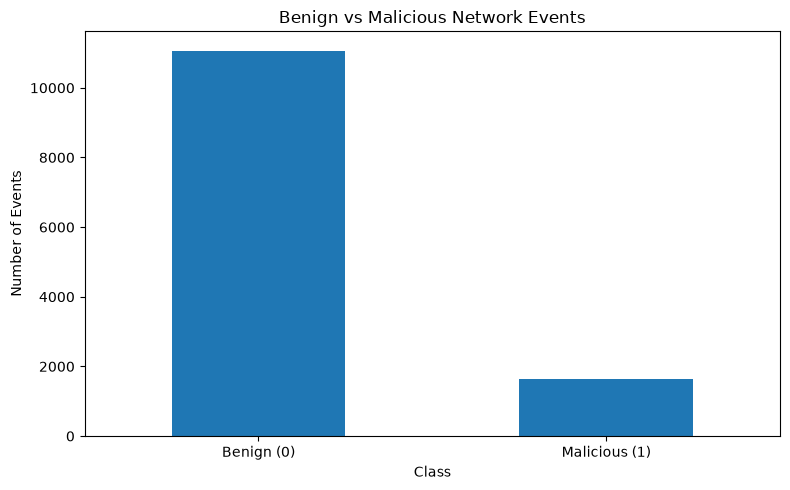

Chart successfully saved to: C:\Users\ryanr\Desktop\real-time-e2e-ml-system-project\reports\figures\class_distribution.png


In [12]:

label_counts = (
    sample["label"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
)

fig, ax = plt.subplots(figsize=(8, 5))

label_counts.plot(
    kind="bar",
    ax=ax,
)

ax.set_title("Benign vs Malicious Network Events")
ax.set_xlabel("Class")
ax.set_ylabel("Number of Events")

ax.set_xticklabels(
    ["Benign (0)", "Malicious (1)"],
    rotation=0,
)

ax.set_ylim(bottom=0)

fig.tight_layout()

# Save using the correct absolute directory.
output_path = (
    FIGURES_DIRECTORY / "class_distribution.png"
)

fig.savefig(
    output_path,
    dpi=150,
    bbox_inches="tight",
)

plt.show()

plt.close(fig)

print(f"Chart successfully saved to: {output_path}")


In [13]:

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Find the A1 project root.
current_directory = Path.cwd().resolve()

PROJECT_ROOT = None

for directory in (
    current_directory,
    *current_directory.parents,
):
    if (directory / "pyproject.toml").is_file():
        PROJECT_ROOT = directory
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate the A1 project root."
    )


# Define the actual figures directory.
FIGURES_DIRECTORY = (
    PROJECT_ROOT / "reports" / "figures"
)

# Create the directory if it does not exist.
FIGURES_DIRECTORY.mkdir(
    parents=True,
    exist_ok=True,
)


print("Project root:")
print(PROJECT_ROOT)

print("\nFigures directory:")
print(FIGURES_DIRECTORY)

print("\nFigures directory exists:")
print(FIGURES_DIRECTORY.is_dir())


Project root:
C:\Users\ryanr\Desktop\real-time-e2e-ml-system-project

Figures directory:
C:\Users\ryanr\Desktop\real-time-e2e-ml-system-project\reports\figures

Figures directory exists:
True


In [14]:

print("Sample dimensions:")
print(sample.shape)

print("\nRequired columns:")

required_columns = [
    "label",
    "attack_cat",
    "stime",
    "ltime",
]

for column in required_columns:
    print(
        f"{column}: "
        f"{column in sample.columns}"
    )

print("\nLabel values:")
print(sorted(sample["label"].dropna().unique()))

print("\nMissing labels:")
print(sample["label"].isna().sum())


Sample dimensions:
(12700, 49)

Required columns:
label: True
attack_cat: True
stime: True
ltime: True

Label values:
[np.int64(0), np.int64(1)]

Missing labels:
0


In [15]:
print(
    (FIGURES_DIRECTORY / "class_distribution.png").is_file()
)

True


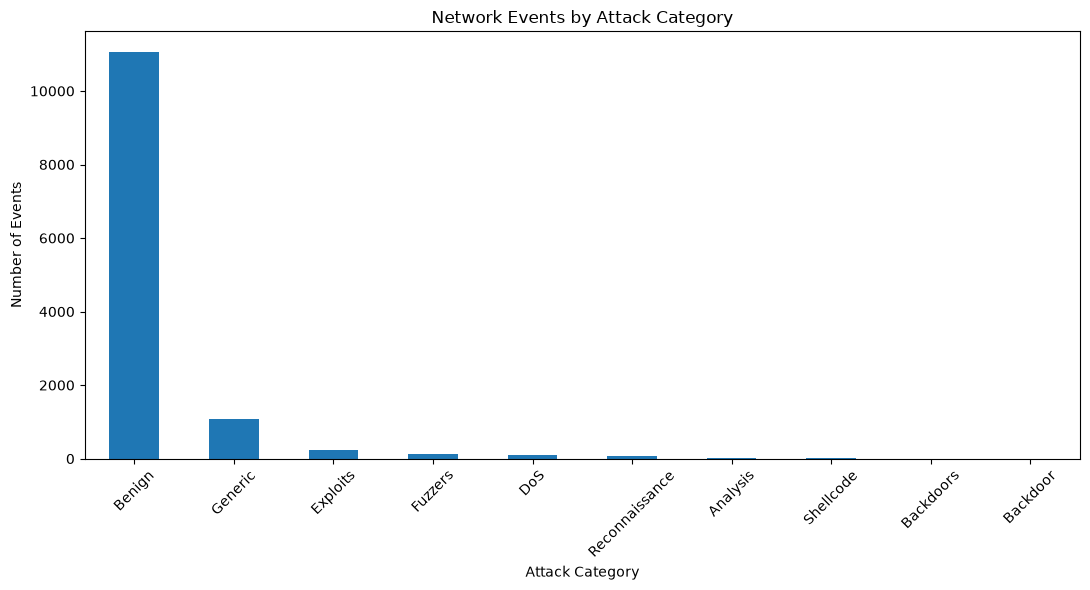

Chart successfully saved to: C:\Users\ryanr\Desktop\real-time-e2e-ml-system-project\reports\figures\attack_categories.png


In [16]:

# Use "Benign" for missing attack categories in the visualization.
# This changes only the plotting representation, not the raw data.

plot_categories = (
    sample["attack_cat"]
    .astype("string")
    .str.strip()
    .fillna("Benign")
)

attack_counts = plot_categories.value_counts()

fig, ax = plt.subplots(figsize=(11, 6))

attack_counts.plot(
    kind="bar",
    ax=ax,
)

ax.set_title("Network Events by Attack Category")
ax.set_xlabel("Attack Category")
ax.set_ylabel("Number of Events")

ax.tick_params(
    axis="x",
    rotation=45,
)

fig.tight_layout()

output_path = (
    FIGURES_DIRECTORY / "attack_categories.png"
)

fig.savefig(
    output_path,
    dpi=150,
    bbox_inches="tight",
)

plt.show()

plt.close(fig)

print(f"Chart successfully saved to: {output_path}")


In [17]:

unique_counts = sample.nunique(
    dropna=False
)

cardinality_report = pd.DataFrame({
    "unique_values": unique_counts,
    "unique_percentage": (
        unique_counts / len(sample) * 100
    ),
})

cardinality_report = (
    cardinality_report.sort_values(
        "unique_values",
        ascending=False,
    )
)

print("Highest-cardinality features:")
display(cardinality_report.head(20))

print("\nSource and destination identifiers:")

for column in ["srcip", "dstip", "sport", "dsport"]:

    if column in sample.columns:
        print(
            f"{column}: "
            f"{sample[column].nunique(dropna=False)} "
            "unique values"
        )


Highest-cardinality features:


,unique_values,unique_percentage
ltime,11600,91.338583
stime,11598,91.322835
sport,9698,76.362205
sload,9002,70.881890
dload,8758,68.960630
dur,8307,65.409449
sintpkt,8148,64.157480
djit,8146,64.141732
dintpkt,7993,62.937008
sjit,7835,61.692913



Source and destination identifiers:
srcip: 33 unique values
dstip: 39 unique values
sport: 9698 unique values
dsport: 3960 unique values


In [18]:

# Recalculate the important statistics for the report.
sample_rows, sample_columns = sample.shape

missing_summary = sample.isna().sum().sort_values(
    ascending=False
)

label_summary = (
    sample["label"]
    .value_counts()
    .sort_index()
)

attack_summary = (
    sample["attack_cat"]
    .astype("string")
    .str.strip()
    .fillna("<MISSING>")
    .value_counts()
)

duplicate_count = int(
    sample.duplicated().sum()
)

numeric_columns = sample.select_dtypes(
    include="number"
).columns.tolist()

numeric_features = [
    column
    for column in numeric_columns
    if column != "label"
]

numeric_summary = (
    sample[numeric_features]
    .describe()
    .T
)

unique_summary = (
    sample.nunique(dropna=False)
    .sort_values(ascending=False)
)

report_lines = [
    "# UNSW-NB15 Exploratory Data Analysis",
    "",
    "## 1. Dataset sample",
    "",
    f"- Sample records: {sample_rows:,}",
    f"- Feature/label columns: {sample_columns}",
    "- Sampling method: deterministic 0.5% sampling ",
    "  from each 100,000-record chunk.",
    "",
    "This is an exploratory sample, not the full ",
    "training or testing dataset.",
    "",
    "## 2. Binary label distribution",
    "",
    label_summary.to_string(),
    "",
    "## 3. Attack category distribution",
    "",
    attack_summary.to_string(),
    "",
    "## 4. Missing values",
    "",
    missing_summary.to_string(),
    "",
    "## 5. Duplicate observations",
    "",
    f"Exact duplicate rows in EDA sample: {duplicate_count:,}",
    "",
    "This count applies to the sample only, not the ",
    "complete original dataset.",
    "",
    "## 6. Numerical feature summary",
    "",
    "```text",
    numeric_summary.to_string(),
    "```",
    "",
    "## 7. Timestamp analysis",
    "",
]

for column, values in timestamp_report.items():

    report_lines.extend([
        f"### {column}",
        "",
        f"- Earliest: {values['earliest']}",
        f"- Latest: {values['latest']}",
        f"- Invalid/unconvertible: {values['invalid_count']}",
        "",
    ])

report_lines.extend([
    "## 8. High-cardinality features",
    "",
    "```text",
    unique_summary.head(20).to_string(),
    "```",
    "",
    "## 9. Initial observations",
    "",
    "- The dataset contains benign and malicious events.",
    "- The binary labels are imbalanced.",
    "- Attack categories are retained separately.",
    "- Missing attack categories must be interpreted ",
    "  carefully because benign records may not have ",
    "  an attack category.",
    "- Backdoor and Backdoors are spelling variants ",
    "  that require documented normalization.",
    "- Source and destination identifiers require ",
    "  further investigation before feature selection.",
    "",
    "## 10. Data-quality limitations and next steps",
    "",
    "- The observed complete dataset contained ",
    "  2,540,047 records.",
    "- The official UNSW page reports 2,540,044 records.",
    "- This discrepancy requires further investigation.",
    "- Full-dataset duplicate and data-quality analysis ",
    "  is still required.",
    "- No raw data has been modified.",
    "",
    "## 11. Evaluation considerations",
    "",
    "- Avoid random splitting where it creates temporal ",
    "  or related-record leakage.",
    "- Examine feature and label distributions over time.",
    "- Preserve an untouched chronological test period.",
    "- Evaluate precision, recall, PR-AUC, FPR and ",
    "  calibration rather than accuracy alone.",
    "",
])

report_path = (
    PROJECT_ROOT / "docs" / "datasets" / "eda-findings.md"
)

report_path.parent.mkdir(
    parents=True,
    exist_ok=True,
)

report_path.write_text(
    "\n".join(report_lines),
    encoding="utf-8",
)

print("EDA findings report created:")
print(report_path)


EDA findings report created:
C:\Users\ryanr\Desktop\real-time-e2e-ml-system-project\docs\datasets\eda-findings.md


In [19]:

# Final A1 EDA verification

required_files = [
    "docs/datasets/unsw_nb15_manifest.json",
    "docs/datasets/unsw_nb15.md",
    "docs/datasets/eda-findings.md",
    "reports/figures/class_distribution.png",
    "reports/figures/attack_categories.png",
]

print("Checking dataset sample...")

assert sample.shape == (12700, 49)
assert sample["label"].notna().all()
assert set(sample["label"].unique()).issubset({0, 1})

print("PASS: Dataset sample")


print("\nChecking feature metadata...")

assert len(feature_names) == 49
assert "attack_cat" in sample.columns
assert "stime" in sample.columns
assert "ltime" in sample.columns

print("PASS: Feature metadata")


print("\nChecking generated files...")

for relative_path in required_files:

    file_path = PROJECT_ROOT / relative_path

    assert file_path.is_file(), (
        f"Missing file: {relative_path}"
    )

    assert file_path.stat().st_size > 0, (
        f"File is empty: {relative_path}"
    )

    print(f"PASS: {relative_path}")


print("\nALL A1 EDA CHECKS PASSED!")


Checking dataset sample...
PASS: Dataset sample

Checking feature metadata...
PASS: Feature metadata

Checking generated files...
PASS: docs/datasets/unsw_nb15_manifest.json
PASS: docs/datasets/unsw_nb15.md
PASS: docs/datasets/eda-findings.md
PASS: reports/figures/class_distribution.png
PASS: reports/figures/attack_categories.png

ALL A1 EDA CHECKS PASSED!
